Status: exploratory

# Does a border correction tighten spatial-domain clusters?

**Idea.** Cluster spots jointly on an expression kNN graph and the physical hex-grid graph, then measure how tight the clusters are. Correct the border effect in the PCs with bosperrus and re-run the joint clustering. Then ask whether the clusters got tighter *because spots changed assignment*.

**Design.** Tightness is the silhouette (per spot, averaged per zone) plus Calinski–Harabasz (whole partition), both computed in PC space. Correcting the space shrinks within-cluster spread by construction, so the old labels (L₀) and the new labels (L_corr) are each scored in both spaces:

| labels \ space | S₀ (uncorrected) | S_corr (corrected) |
|---|---|---|
| L₀ | A | B |
| L_corr | C | D |

- **D − B: reassignment effect.** This is the main result.
- **B − A:** built in by the correction. It is not evidence.
- **C − A:** sensitivity check, with the new labels scored in the original space.

Leiden reassigns spots even without any correction (seed variation), so §6 compares D − B against a seed null.

**Correction.** Exponential saturation vs. constant (AIC) per PC, in both directions, as in bosperrus' `correct_layer`. The reach of each fit is d₉₅ = ln 20 / b, the distance at which 95% of the border–plateau gap has closed. Two variants:
- **all:** every PC where exponential saturation wins;
- **short:** only PCs with d₉₅ ≤ 3 buffer elbows (300 µm). PCs with a longer reach are anatomical gradients across the section rather than border artifacts.

**Data:** `sq.datasets.visium_hne_adata()` (adult mouse brain, coronal, 2688 spots, 100 µm Visium pitch).

**Writes:** `../../results/exploratory/boundary_effects_clustering/` and `../../result_plots/exploratory/boundary_effects_clustering/`.

**Runtime:** about 2 minutes.

The previous, longer version of this notebook is in git history. Its outputs are in `results/archive/boundary_effects_clustering_pre_reroll/`.

In [1]:
import json
import pathlib
import warnings

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_samples, calinski_harabasz_score

from bosperrus import Flow
from bosperrus.fit import ConstantFit, ExponentialSaturationFit, PiecewiseLinearFit
from bosperrus.anndata_api import identify_analysis_buffer_from_filtered

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="bosperrus.evaluate_fit")  # inf - inf for tiny fragments
sc.settings.verbosity = 0

RNG_SEED = 0
N_PCS = 30
N_TOP_GENES = 2000
ALPHA = 0.2               # weight of the spatial graph in the joint graph (sc-best-practices example)
LEIDEN_RESOLUTION = 1.0   # fixed; the cluster count may differ between clusterings
SPOT_PITCH_UM = 100.0     # Visium centre-to-centre distance
SHORT_REACH_ELBOWS = 3    # short reach: d95 <= 3 buffer elbows
N_SEEDS = 10              # Leiden seeds for the null

OUT_DIR = pathlib.Path("../../results/exploratory/boundary_effects_clustering")
PLOT_DIR = pathlib.Path("../../result_plots/exploratory/boundary_effects_clustering")
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
FIT_PALETTE = json.loads(pathlib.Path("../../fit_palette.json").read_text())

/home/woody/iwbn/iwbn007h/bosperrus/truncated_graphs/.pixi/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/woody/iwbn/iwbn007h/bosperrus/truncated_graphs/.pixi/envs/default/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
def preprocess(raw_counts):
    # normalize_total -> log1p -> HVGs -> PCA
    tmp = ad.AnnData(raw_counts.copy())
    tmp.obs_names, tmp.var_names = adata.obs_names, adata.raw.var_names
    sc.pp.normalize_total(tmp)
    sc.pp.log1p(tmp)
    sc.pp.highly_variable_genes(tmp, n_top_genes=N_TOP_GENES, flavor="seurat")
    tmp = tmp[:, tmp.var["highly_variable"]].copy()
    sc.pp.pca(tmp, n_comps=N_PCS, random_state=RNG_SEED)
    return tmp


def joint_leiden(pca, seed=RNG_SEED):
    # expression kNN graph + hex-grid spatial graph, joint Leiden (sc-best-practices "combined graph")
    tmp = ad.AnnData(np.zeros((pca.shape[0], 1)))
    tmp.obsm["X_pca"] = pca
    sc.pp.neighbors(tmp, use_rep="X_pca", random_state=RNG_SEED)
    joint = (1 - ALPHA) * tmp.obsp["connectivities"] + ALPHA * adata.obsp["spatial_connectivities"]
    sc.tl.leiden(tmp, adjacency=joint, resolution=LEIDEN_RESOLUTION, random_state=seed)
    return tmp.obs["leiden"].to_numpy()


def tightness(space, labels):
    # mean silhouette per zone (and over all spots) + Calinski-Harabasz of the whole partition
    sil = silhouette_samples(space, labels)
    out = {f"silhouette {z}": sil[zone == z].mean() for z in ZONES}
    out["silhouette all"] = sil.mean()
    out["Calinski-Harabasz"] = calinski_harabasz_score(space, labels)
    return out


def changed_spots(old, new):
    # cluster names are arbitrary and counts differ: a spot changed if its new cluster's
    # majority old cluster is not its own old cluster
    majority = pd.crosstab(new, old).idxmax(axis=1)
    return majority.loc[new].to_numpy() != old


def d95_expsat(b):
    # exp_sat = a (1 - exp(-b d)) + c closes 95% of the border-plateau gap at d = ln(20) / b
    return np.log(20) / b

## 1. Border and buffer from summed counts

The footprint, border spots and border distance come from bosperrus on the Visium hex grid (`array_row`/`array_col`, 100 µm per step). `identify_analysis_buffer_from_filtered` fits constant vs. piecewise linear to `log1p(total counts)` and flags the spots inside the elbow.

Summed counts are used only to *find* the border effect, not to correct it. A per-spot rescaling of the counts is cancelled by `normalize_total`.

In [3]:
adata = sq.datasets.visium_hne_adata()
raw_counts = adata.raw.X.tocsr().astype(np.float64)
adata.obs["n_counts"] = np.asarray(raw_counts.sum(axis=1)).ravel()
adata.obs["log1p_n_counts"] = np.log1p(adata.obs["n_counts"])

identify_analysis_buffer_from_filtered(
    adata, score="log1p_n_counts", grid_type="hex", bin_size_um=SPOT_PITCH_UM,
    max_hole_area_um2=None,  # hole filling is implemented for rectangular grids only
)
buffer_fit = adata.uns["analysis_buffer_fit"]["per_component"]
main = max(buffer_fit, key=lambda k: buffer_fit[k]["n_spots"])
fit = buffer_fit[main]
elbow_um = fit["elbow_um"]
m, c = fit["params"]["piecewise_linear_m"], fit["params"]["piecewise_linear_c"]
d = adata.obs["distance_to_border"].to_numpy()

zone_all = np.where(adata.obs["border"], "border", np.where(adata.obs["analysis_buffer"], "buffer", "interior"))
ZONES = [z for z in ["border", "buffer", "interior"] if (zone_all == z).any()]
zone = zone_all
SHORT_REACH_UM = SHORT_REACH_ELBOWS * elbow_um

print(f"components: {adata.obs['components'].value_counts().to_dict()} (main section + tiny fragments)")
print(f"main section: {fit['best_fit_type']}, elbow = {elbow_um:.0f} um -> short-reach threshold {SHORT_REACH_UM:.0f} um")
print(f"total counts at the border are {1 - np.exp(-m * elbow_um):.0%} below the plateau")
print("zones:", pd.Series(zone).value_counts().to_dict())

components: {0: 2679, 1: 5, 2: 4} (main section + tiny fragments)
main section: Piecewise Linear Fit, elbow = 100 um -> short-reach threshold 300 um
total counts at the border are 30% below the plateau
zones: {'interior': 2407, 'border': 281}


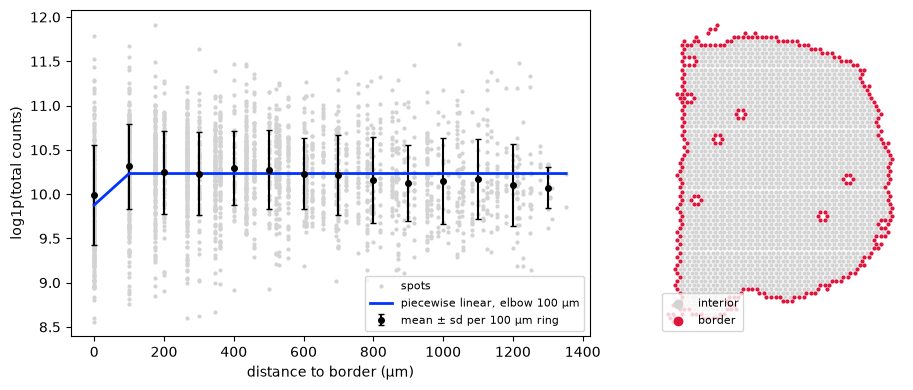

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1.3, 1]})
ring_um = np.floor(d / SPOT_PITCH_UM) * SPOT_PITCH_UM  # 100 um distance rings
stats = adata.obs.groupby(ring_um)["log1p_n_counts"].agg(["mean", "std", "size"]).reset_index(names="ring")
stats = stats[stats["size"] >= 10]
ax = axs[0]
ax.scatter(d, adata.obs["log1p_n_counts"], s=4, color="lightgray", rasterized=True, label="spots")
ax.errorbar(stats["ring"], stats["mean"], yerr=stats["std"], fmt="o", ms=4, color="black",
            capsize=2, label="mean ± sd per 100 µm ring")
d_grid = np.linspace(0, d.max(), 400)
ax.plot(d_grid, PiecewiseLinearFit.piecewise_plateau(d_grid, elbow_um, m, c),
        color=FIT_PALETTE["Piecewise Linear Fit"], lw=2, label=f"piecewise linear, elbow {elbow_um:.0f} µm")
ax.set_xlabel("distance to border (µm)")
ax.set_ylabel("log1p(total counts)")
ax.legend(fontsize=8, loc="lower right")

ax = axs[1]
xy = adata.obsm["spatial"]
for z, col in [("interior", "lightgray"), ("buffer", "orange"), ("border", "crimson")]:
    sel = zone == z
    if sel.any():
        ax.scatter(xy[sel, 0], xy[sel, 1], s=4, color=col, label=z)
ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
ax.legend(fontsize=8, loc="lower left", markerscale=3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "library_size_border_effect.svg", bbox_inches="tight")
plt.show()

## 2. Baseline joint clustering

Labels **L₀** are computed in the uncorrected PC space **S₀**.

In [5]:
baseline = preprocess(raw_counts)
sq.gr.spatial_neighbors(adata, coord_type="grid", n_neighs=6)
S0 = baseline.obsm["X_pca"]
L0 = joint_leiden(S0)
print(f"L0: {len(np.unique(L0))} clusters")

INFO     Creating graph using `None` transform and `1` libraries.                                                  


L0: 15 clusters


## 3. Per-PC border fits and their reach (d₉₅)

Each PC is fit with exponential saturation vs. constant against border distance (AIC). The fit runs in both directions: a PC's sign is arbitrary, so a "depression" and an "elevation" at the border are the same thing.

- If d₉₅ is larger than the maximal border distance, the curve never reaches its plateau inside the section. That PC is a gradient across the whole section, and its correction extrapolates toward an asymptote outside the data.
- The right panel gives context: in a coronal brain section the annotated regions are layered by border distance.

In [6]:
pc_names = [f"PC{i}" for i in range(N_PCS)]
dist_series = pd.Series(d, index=adata.obs_names, name="distance_to_border")
flow_pc = Flow.from_distances_and_scores(
    distances=dist_series, scores=pd.DataFrame(S0, columns=pc_names, index=adata.obs_names)
)
flow_pc.flow(fits=[ConstantFit, ExponentialSaturationFit])

pc_fits = pd.DataFrame({
    "best_fit_type": [flow_pc.best_fits[p].name for p in pc_names],
    "a": [flow_pc.best_fits[p].params.get("exponential_saturation_a", np.nan) for p in pc_names],
    "b": [flow_pc.best_fits[p].params.get("exponential_saturation_b", np.nan) for p in pc_names],
    "observed_effect_strength": [flow_pc.best_fits[p].observed_effect_strength for p in pc_names],
}, index=pc_names)
pc_fits["d95_um"] = d95_expsat(pc_fits["b"])
corrected_pcs = pc_fits.index[pc_fits["best_fit_type"] == "Exponential Saturation Fit"]
short_pcs = pc_fits.index[pc_fits["d95_um"] <= SHORT_REACH_UM]
pc_fits["reach"] = np.select(
    [pc_fits.index.isin(short_pcs), pc_fits.index.isin(corrected_pcs)], ["short", "long"], "no effect"
)
pc_fits.to_csv(OUT_DIR / "pc_fits.csv")
print(f"exponential saturation wins for {len(corrected_pcs)} / {N_PCS} PCs; "
      f"short reach (d95 <= {SHORT_REACH_UM:.0f} um): {list(short_pcs)}; "
      f"d95 beyond the maximal distance ({d.max():.0f} um): {(pc_fits['d95_um'] > d.max()).sum()}")
pc_fits.round(4)

exponential saturation wins for 25 / 30 PCs; short reach (d95 <= 300 um): ['PC3', 'PC4', 'PC5', 'PC11', 'PC15', 'PC16', 'PC24', 'PC28']; d95 beyond the maximal distance (1353 um): 13


,best_fit_type,a,b,observed_effect_strength,d95_um,reach
PC0,Exponential Saturation Fit,12527.0573,0.0000,-3.1679,4.052552e+06,long
PC1,Exponential Saturation Fit,3.2321,0.0016,30.2884,1.826086e+03,long
PC2,Exponential Saturation Fit,27.1469,0.0002,-3.5870,1.757197e+04,long
PC3,Exponential Saturation Fit,-3.4769,0.0122,1.4325,2.456883e+02,short
PC4,Exponential Saturation Fit,1.5033,0.0132,1.4074,2.267841e+02,short
PC5,Exponential Saturation Fit,-0.7235,0.0121,1.4356,2.479653e+02,short
PC6,Exponential Saturation Fit,2.7617,0.0009,-8.1817,3.378260e+03,long
PC7,Exponential Saturation Fit,2.1840,0.0015,465.1949,2.019074e+03,long
PC8,Exponential Saturation Fit,947.2922,0.0000,-3.1679,4.052552e+06,long
PC9,Exponential Saturation Fit,2.3721,0.0012,-21.3651,2.409801e+03,long


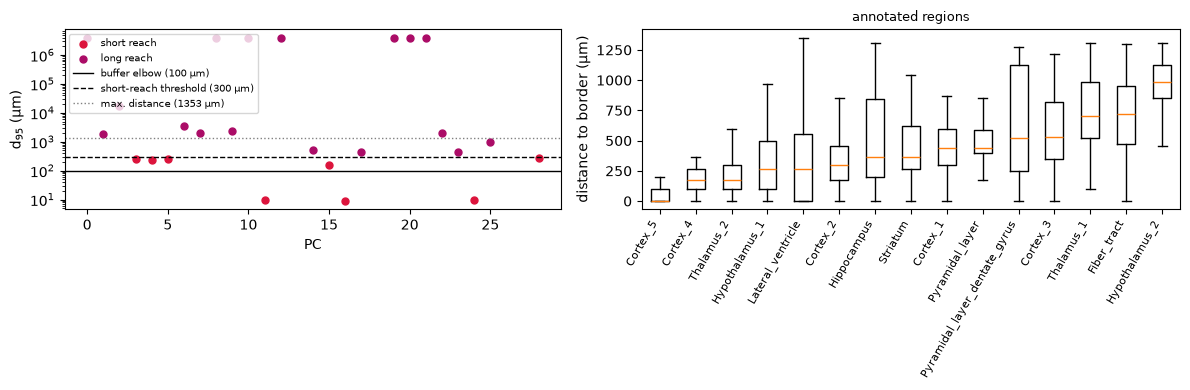

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.2, 1.3]})
ax = axs[0]
reach_color = {"short": "crimson", "long": FIT_PALETTE["Exponential Saturation Fit"]}
for reach, col in reach_color.items():
    sel = pc_fits[pc_fits["reach"] == reach]
    ax.scatter(np.arange(N_PCS)[pc_fits["reach"] == reach], sel["d95_um"], color=col, s=25, label=f"{reach} reach")
ax.axhline(elbow_um, color="black", lw=1, label=f"buffer elbow ({elbow_um:.0f} µm)")
ax.axhline(SHORT_REACH_UM, color="black", lw=1, ls="--", label=f"short-reach threshold ({SHORT_REACH_UM:.0f} µm)")
ax.axhline(d.max(), color="gray", lw=1, ls=":", label=f"max. distance ({d.max():.0f} µm)")
ax.set_yscale("log")
ax.set_xlabel("PC")
ax.set_ylabel("d$_{95}$ (µm)")
ax.legend(fontsize=7, loc="upper left")

ax = axs[1]
order = adata.obs.groupby("cluster", observed=True)["distance_to_border"].median().sort_values().index
ax.boxplot([d[adata.obs["cluster"] == k] for k in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("distance to border (µm)")
ax.set_title("annotated regions", fontsize=9)
plt.tight_layout()
plt.savefig(PLOT_DIR / "pc_reach.svg", bbox_inches="tight")
plt.show()

## 4. Corrected spaces and reclustering

- **S_all:** every PC where exponential saturation wins is corrected toward its asymptote. The other PCs pass through unchanged.
- **S_short:** only the short-reach PCs are corrected.

Each space is reclustered with the same Leiden settings.

In [8]:
S_all = S0.copy()
for i, p in enumerate(pc_names):
    if p in corrected_pcs:
        S_all[:, i] = flow_pc.observations[f"BOSPERRUS corrected {p}"].to_numpy()
S_short = S0.copy()
for i, p in enumerate(pc_names):
    if p in short_pcs:
        S_short[:, i] = S_all[:, i]

spaces = {"all": S_all, "short": S_short}
labels_corr = {v: joint_leiden(S) for v, S in spaces.items()}
for v in spaces:
    ch = changed_spots(L0, labels_corr[v])
    print(f"{v}: {len(np.unique(labels_corr[v]))} clusters, {ch.mean():.1%} of spots changed cluster "
          + ", ".join(f"{z} {ch[zone == z].mean():.1%}" for z in ZONES))

all: 15 clusters, 16.4% of spots changed cluster border 23.1%, interior 15.6%
short: 13 clusters, 16.1% of spots changed cluster border 32.7%, interior 14.2%


## 5. Tightness: 2×2 per variant

In [9]:
rows = []
for v, S_corr in spaces.items():
    Lc = labels_corr[v]
    for cell, lab, space_name, space in [("A", L0, "S0", S0), ("B", L0, "S_corr", S_corr),
                                         ("C", Lc, "S0", S0), ("D", Lc, "S_corr", S_corr)]:
        rows.append({"variant": v, "cell": cell, "labels": "L0" if lab is L0 else "L_corr", "space": space_name,
                     "n_clusters": len(np.unique(lab)), **tightness(space, lab)})
table = pd.DataFrame(rows).set_index(["variant", "cell"])
table.to_csv(OUT_DIR / "tightness_2x2.csv")

metrics = [f"silhouette {z}" for z in ZONES] + ["silhouette all", "Calinski-Harabasz"]
deltas = pd.concat({
    "D - B (reassignment)": table.xs("D", level="cell")[metrics] - table.xs("B", level="cell")[metrics],
    "B - A (built in)": table.xs("B", level="cell")[metrics] - table.xs("A", level="cell")[metrics],
    "C - A (sensitivity)": table.xs("C", level="cell")[metrics] - table.xs("A", level="cell")[metrics],
}, names=["contrast"]).swaplevel().sort_index()
deltas.to_csv(OUT_DIR / "tightness_deltas.csv")
display(table.round(3))
deltas.round(3)

labels   space  n_clusters  silhouette border  \
variant cell                                                  
all     A         L0      S0          15              0.059   
        B         L0  S_corr          15              0.049   
        C     L_corr      S0          15              0.104   
        D     L_corr  S_corr          15              0.107   
short   A         L0      S0          15              0.059   
        B         L0  S_corr          15              0.031   
        C     L_corr      S0          13              0.119   
        D     L_corr  S_corr          13              0.118   

              silhouette interior  silhouette all  Calinski-Harabasz  
variant cell                                                          
all     A                   0.140           0.131            331.965  
        B                   0.115           0.109            267.372  
        C                   0.128           0.126            332.087  
        D                   0.118           0.117            289.271  
short   A                   0.140           0.131            331.965  
        B                   0.140           0.129            333.884  
        C                   0.155           0.151            384.912  
        D                   0.153           0.149            392.209

silhouette border  silhouette interior  \
variant contrast                                                       
all     B - A (built in)                 -0.010               -0.024   
        C - A (sensitivity)               0.045               -0.011   
        D - B (reassignment)              0.058                0.002   
short   B - A (built in)                 -0.028                0.000   
        C - A (sensitivity)               0.060                0.015   
        D - B (reassignment)              0.087                0.013   

                              silhouette all  Calinski-Harabasz  
variant contrast                                                 
all     B - A (built in)              -0.023            -64.593  
        C - A (sensitivity)           -0.005              0.122  
        D - B (reassignment)           0.008             21.899  
short   B - A (built in)              -0.003              1.919  
        C - A (sensitivity)            0.020             52.947  
        D - B (reassignment)           0.021             58.325

## 6. Seed null: is D − B larger than Leiden's own variability?

For each seed s, L₀ˢ comes from clustering S₀ and L_corrˢ from clustering S_corr, and the reassignment effect is Dˢ − Bˢ, both scored in S_corr. The null is the seed noise of the uncorrected labels in that same space: T(S_corr, L₀ˢ) − T(S_corr, L₀⁰) for s ≥ 1. The changed-spot fraction gets the same comparison: L₀ˢ vs. L_corrˢ against L₀⁰ vs. L₀ˢ.

In [10]:
seed_rows = []
L0_seeds = {s: joint_leiden(S0, seed=s) for s in range(N_SEEDS)}
for v, S_corr in spaces.items():
    T_ref = tightness(S_corr, L0_seeds[0])
    for s in range(N_SEEDS):
        Lc_s = joint_leiden(S_corr, seed=s)
        T_B, T_D = tightness(S_corr, L0_seeds[s]), tightness(S_corr, Lc_s)
        seed_rows.append({"variant": v, "seed": s, "kind": "D - B",
                          "changed": changed_spots(L0_seeds[s], Lc_s).mean(),
                          **{k: T_D[k] - T_B[k] for k in metrics}})
        if s > 0:
            seed_rows.append({"variant": v, "seed": s, "kind": "null",
                              "changed": changed_spots(L0_seeds[0], L0_seeds[s]).mean(),
                              **{k: T_B[k] - T_ref[k] for k in metrics}})
seeds = pd.DataFrame(seed_rows)
seeds.to_csv(OUT_DIR / "tightness_seed_null.csv", index=False)
seeds.groupby(["variant", "kind"])[["changed"] + metrics].agg(["mean", "min", "max"]).round(3).T

variant                      all           short        
kind                       D - B    null   D - B    null
changed             mean   0.145   0.156   0.097   0.156
                    min    0.056   0.096   0.017   0.096
                    max    0.245   0.222   0.172   0.222
silhouette border   mean   0.022   0.031   0.032   0.048
                    min   -0.009  -0.024  -0.002   0.004
                    max    0.068   0.055   0.087   0.079
silhouette interior mean   0.020  -0.007   0.004   0.002
                    min   -0.002  -0.019  -0.026  -0.010
                    max    0.042   0.014   0.022   0.021
silhouette all      mean   0.021  -0.003   0.007   0.007
                    min   -0.002  -0.018  -0.022  -0.006
                    max    0.045   0.018   0.027   0.025
Calinski-Harabasz   mean  15.069   7.118  19.031  13.861
                    min  -12.985 -11.375  -1.348  -8.439
                    max   44.168  21.521  58.325  32.447

## 7. Figures

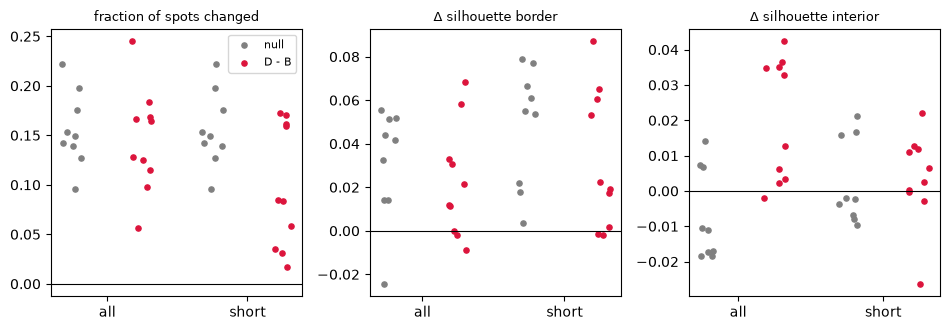

In [11]:
show = ["changed"] + [f"silhouette {z}" for z in ZONES]
fig, axs = plt.subplots(1, len(show), figsize=(3.2 * len(show), 3.4))
rng = np.random.default_rng(RNG_SEED)
for ax, metric in zip(axs, show):
    for j, v in enumerate(spaces):
        for k, (kind, col) in enumerate([("null", "gray"), ("D - B", "crimson")]):
            vals = seeds.loc[(seeds["variant"] == v) & (seeds["kind"] == kind), metric]
            x = 2 * j + k + rng.uniform(-0.15, 0.15, len(vals))
            ax.scatter(x, vals, s=14, color=col, label=kind if (j == 0 and metric == show[0]) else None)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks([0.5, 2.5], [f"{v}" for v in spaces])
    ax.set_title("fraction of spots changed" if metric == "changed" else metric.replace("silhouette", "Δ silhouette"),
                 fontsize=9)
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(PLOT_DIR / "reassignment_vs_seed_null.svg", bbox_inches="tight")
plt.show()

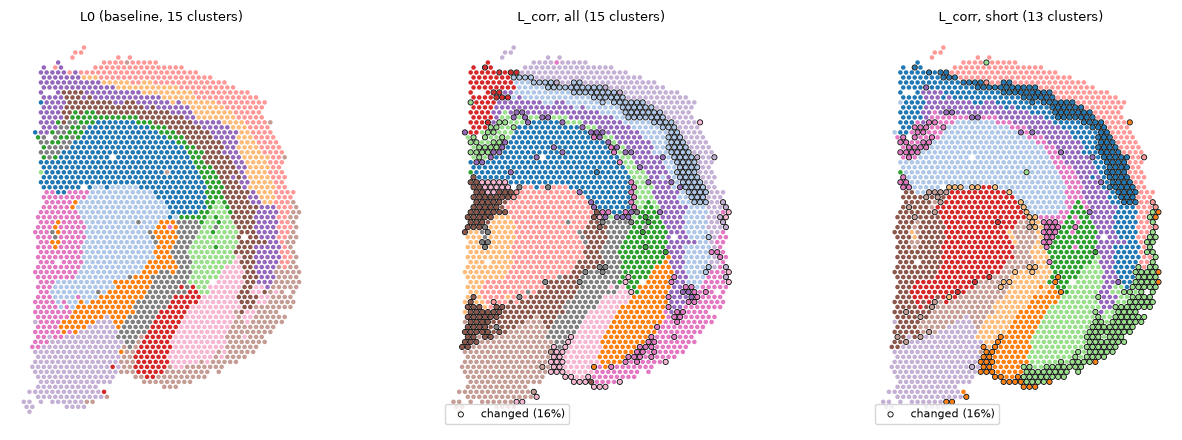

In [12]:
fig, axs = plt.subplots(1, 1 + len(spaces), figsize=(4.5 * (1 + len(spaces)), 4.5))
cmap = plt.get_cmap("tab20")
def draw(ax, labels, title, changed=None):
    codes = pd.Categorical(labels).codes
    ax.scatter(xy[:, 0], xy[:, 1], s=5, c=cmap(codes % 20), rasterized=True)
    if changed is not None:
        ax.scatter(xy[changed, 0], xy[changed, 1], s=14, facecolor="none", edgecolor="black", lw=0.6,
                   label=f"changed ({changed.mean():.0%})")
        ax.legend(fontsize=8, loc="lower left")
    ax.set_title(title, fontsize=9)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
draw(axs[0], L0, f"L0 (baseline, {len(np.unique(L0))} clusters)")
for ax, v in zip(axs[1:], spaces):
    draw(ax, labels_corr[v], f"L_corr, {v} ({len(np.unique(labels_corr[v]))} clusters)",
         changed=changed_spots(L0, labels_corr[v]))
plt.tight_layout()
plt.savefig(PLOT_DIR / "clusterings_changed_spots.svg", bbox_inches="tight")
plt.show()

## Conclusion

**Null result on classic Visium: there is no evidence that correcting the border effect tightens clusters through reassignment.**

**What holds up**
- Library size drops by about 30% at the border, with an elbow at 100 µm (one spot).
- The exponential-saturation reach d₉₅ separates the PCs cleanly:
  - 8 PCs are short-reach (≤ 300 µm);
  - 13 PCs have d₉₅ beyond the maximal distance, i.e. linear gradients across the section (anatomy).

**Why it is a null**
1. **Leiden seed noise is as large as the effect.**
   - Re-running the *uncorrected* clustering with another seed changes 16% of spots on average (range 10–22%).
   - The correction changes 15% ("all") or 10% ("short").
   - Changed spots form whole bands where clusters split or merge, not border spots switching cluster.
2. **Border silhouette stays within the seed null.** Seed-averaged D − B for border spots is +0.022 ("all") and +0.032 ("short"), against null means of +0.031 and +0.048. The distributions overlap completely.
3. **The single-seed 2×2 table (§5) is misleading.** "short" D − B = +0.087 for border spots is the maximum over the 10 seeds; seed 0 happened to be the best one.
4. **The only effect that separates from the null is in the wrong place, and for the wrong reason.**
   - Interior silhouette D − B in "all" is +0.020, against a null of −0.007.
   - That variant also removes the long-reach anatomical gradients (B − A = −0.024), so the new labels are adapting to a space with less anatomy in it. This is not the border hypothesis.

**Weaknesses of this setup**
- **The border effect sits at the resolution limit.**
  - At a 100 µm pitch it covers exactly one spot ring, so the buffer zone is empty and only 281 spots carry the signal.
  - PC11, PC16 and PC24 have d₉₅ ≈ 9 µm, effectively a step between the border ring and everything else.
- **Long-reach exponential-saturation fits are degenerate.** With b → 0 and a ≈ 10³–10⁴ they are linear trends, and their correction extrapolates toward an asymptote far outside the data. Only the "short" variant is meaningful.
- **Possible bosperrus bug in `observed_effect_strength`.** It is exactly −3.1679 for six PCs and exactly 1.2643 for three. The metric looks degenerate when a fit sits at a limit (b → 0 or b very large). This is to be checked in bosperrus.
- **The changed-spot count is fragile.** "Changed" uses majority mapping between clusters, so a single split or merge inflates it.

**Next steps**
- Treat this as a null result on classic Visium. A one-spot border effect is too thin to move a clustering beyond Leiden's own variability.
- For a real test, run the same design on **Visium HD at 8 µm**, where elbows span several bins and the border zone has thousands of bins.
- Report seed-averaged D − B against the null as the primary readout, never a single seed.
- Optionally use consensus Leiden over several seeds to reduce the noise.